In [24]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage

In [25]:
load_dotenv()

True

In [26]:
class chatState(TypedDict):
    topic:str
    joke:str
    explaination:str

In [27]:
llm=ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [28]:
def gen_joke(state:chatState):
    prompt=f"generate a joke based on the topic : {state['topic']}"
    joke=llm.invoke(prompt).content
    return{
        'joke':joke
    }


In [29]:
def gen_exp(state:chatState):
    prompt=f"explain this joke {state['joke']} generated on this topic {state['topic']}"
    explaination=llm.invoke(prompt).content
    return{
        'explaination':explaination
    }

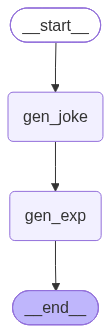

In [30]:
graph=StateGraph(chatState)

graph.add_node("gen_joke",gen_joke)
graph.add_node("gen_exp",gen_exp)

graph.add_edge(START,'gen_joke')
graph.add_edge('gen_joke','gen_exp')
graph.add_edge('gen_exp',END)

checkpointer=InMemorySaver()

workflow=graph.compile(checkpointer=checkpointer)
workflow


In [31]:
config1={"configurable":{"thread_id":"1"}}
initial_state={'topic':"apple"}
workflow.invoke(initial_state,config=config1)

{'topic': 'apple',
 'joke': [{'type': 'text',
   'text': 'Why do apple trees make terrible secret agents?\n\nBecause they always spill the beans—er, seeds!',
   'extras': {'signature': 'EpYBCpMBAWkUfRNkWWFBhQD0JOudnTJM7HQ8FMQ4d/lhXRJSDPK0c0xIO8ZYVv9ApIW5YrWJHvOzJPGD9NI5nlgdCB4Ln1GvnO4UbtVrHU1RiNZN2UxJhUH9pDqTuLRkwiJtOPPNKKxBYcTvahchZywaUypylxQ1RjgCe5DUYIsuD+A94xxd6oQs1L7vDknrwO02teDQLqCs'}}],
 'explaination': [{'type': 'text',
   'text': 'This is a classic "dad joke" that relies on a **pun** (a play on words) and a mix-up of idioms. Here is the breakdown of why it\'s funny:\n\n1. **"Spill the beans":** This is a common English idiom that means to reveal a secret. \n2. **Apple trees:** Apple trees don\'t grow beans; they grow *apples*, which contain *seeds*. \n3. **The joke\'s twist:** The punchline starts to use the common phrase ("spill the *beans*"), but catches itself mid-sentence ("er...") to correct it to the part of the apple that actually gets "spilled" or dropped—the **seeds**.

In [32]:
second_state={'topic':"bananna"}
workflow.invoke(second_state,config=config1)

{'topic': 'bananna',
 'joke': [{'type': 'text',
   'text': "Why did the banana go to the doctor?\n\nBecause it wasn't peeling well!",
   'extras': {'signature': 'EpYBCpMBAWkUfRONd/L1brQn9jl5FgYqBBbp5yi0mLRh3rJPibzeBgQDfaocei0es5a6Un8A8ETGfzjeM/g3+IbVrbl78is3GAgh2KsKaSvBdmpjIKDgi4nEAk0cEu92EwZN3v9QdQd8sA82n9anc4qSDdFAPQ4w+aRaD7+Nw/yBcipmfhBc0oLVKzKwHGKix9vG5VxNFRSh'}}],
 'explaination': [{'type': 'text',
   'text': 'This is a classic, family-friendly pun! Here is why it\'s funny:\n\n1. **The Setup ("Why did the banana go to the doctor?")**: This sets up a common scenario where someone is sick and needs medical help.\n2. **The Punchline ("Because it wasn\'t peeling well!")**: This relies on a play on words (a pun):\n   * **"Peeling well"** sounds almost identical to **"feeling well"** (feeling healthy).\n   * Because the main character is a banana, it literally has a **peel** (its skin), which ties the medical complaint back to its identity as a fruit. \n\nIn short, the banana went to th

In [33]:
workflow.get_state(config=config1)

StateSnapshot(values={'topic': 'bananna', 'joke': [{'type': 'text', 'text': "Why did the banana go to the doctor?\n\nBecause it wasn't peeling well!", 'extras': {'signature': 'EpYBCpMBAWkUfRONd/L1brQn9jl5FgYqBBbp5yi0mLRh3rJPibzeBgQDfaocei0es5a6Un8A8ETGfzjeM/g3+IbVrbl78is3GAgh2KsKaSvBdmpjIKDgi4nEAk0cEu92EwZN3v9QdQd8sA82n9anc4qSDdFAPQ4w+aRaD7+Nw/yBcipmfhBc0oLVKzKwHGKix9vG5VxNFRSh'}}], 'explaination': [{'type': 'text', 'text': 'This is a classic, family-friendly pun! Here is why it\'s funny:\n\n1. **The Setup ("Why did the banana go to the doctor?")**: This sets up a common scenario where someone is sick and needs medical help.\n2. **The Punchline ("Because it wasn\'t peeling well!")**: This relies on a play on words (a pun):\n   * **"Peeling well"** sounds almost identical to **"feeling well"** (feeling healthy).\n   * Because the main character is a banana, it literally has a **peel** (its skin), which ties the medical complaint back to its identity as a fruit. \n\nIn short, the banana 

In [35]:
list(workflow.get_state_history(config=config1))

[StateSnapshot(values={'topic': 'bananna', 'joke': [{'type': 'text', 'text': "Why did the banana go to the doctor?\n\nBecause it wasn't peeling well!", 'extras': {'signature': 'EpYBCpMBAWkUfRONd/L1brQn9jl5FgYqBBbp5yi0mLRh3rJPibzeBgQDfaocei0es5a6Un8A8ETGfzjeM/g3+IbVrbl78is3GAgh2KsKaSvBdmpjIKDgi4nEAk0cEu92EwZN3v9QdQd8sA82n9anc4qSDdFAPQ4w+aRaD7+Nw/yBcipmfhBc0oLVKzKwHGKix9vG5VxNFRSh'}}], 'explaination': [{'type': 'text', 'text': 'This is a classic, family-friendly pun! Here is why it\'s funny:\n\n1. **The Setup ("Why did the banana go to the doctor?")**: This sets up a common scenario where someone is sick and needs medical help.\n2. **The Punchline ("Because it wasn\'t peeling well!")**: This relies on a play on words (a pun):\n   * **"Peeling well"** sounds almost identical to **"feeling well"** (feeling healthy).\n   * Because the main character is a banana, it literally has a **peel** (its skin), which ties the medical complaint back to its identity as a fruit. \n\nIn short, the banana